In [99]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [100]:
df = pd.read_csv(r'/Users/pawn/Desktop/NTI/Student_Performance.csv')

In [101]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


In [102]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        8428 non-null   object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  7144 non-null   float64
 5   Performance Index                 10000 non-null  int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [103]:
df.shape

(10000, 6)

In [104]:
df.columns

Index(['Hours Studied', 'Previous Scores', 'Extracurricular Activities',
       'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index'],
      dtype='object')

In [105]:
# df.drop(['Unnamed: 0'] , axis=1 , inplace=True)

In [106]:
df.isnull().sum()

Hours Studied                          0
Previous Scores                        0
Extracurricular Activities          1572
Sleep Hours                            0
Sample Question Papers Practiced    2856
Performance Index                      0
dtype: int64

In [107]:
df.duplicated().sum()

np.int64(132)

In [108]:
df.drop_duplicates(inplace = True)

In [109]:
df.reset_index(drop=True, inplace=True)

In [110]:
df.duplicated().sum()

np.int64(0)

In [111]:
df.isnull().sum().sort_values(ascending=False).head(12)

Sample Question Papers Practiced    2778
Extracurricular Activities          1563
Hours Studied                          0
Previous Scores                        0
Sleep Hours                            0
Performance Index                      0
dtype: int64

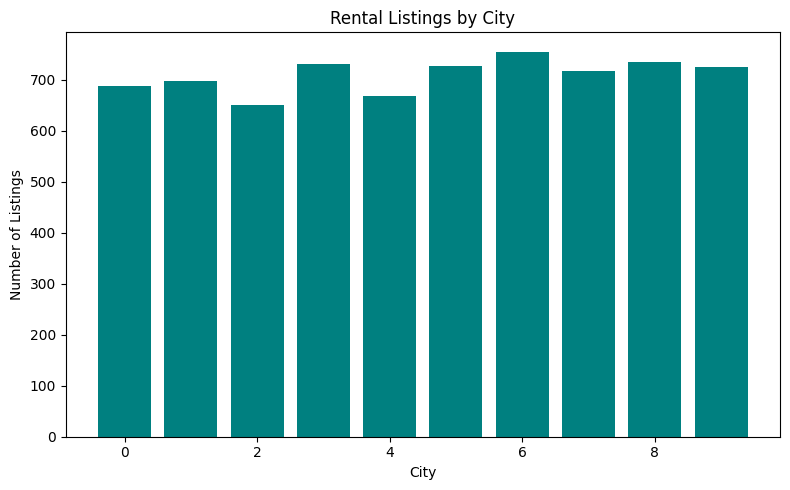

In [112]:
city_counts = df['Sample Question Papers Practiced'].value_counts()
plt.figure(figsize=(8, 5))
plt.bar(city_counts.index, city_counts.values, color='teal')
plt.title('Rental Listings by City')
plt.xlabel('City')
plt.ylabel('Number of Listings')
plt.tight_layout()
plt.show()

In [113]:
df['Sample Question Papers Practiced'].skew()

np.float64(-0.04148768921377276)

In [114]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
# strategy = 'median', 'mean', 'constant', 'most_frequent'
imputer.fit(df[['Sample Question Papers Practiced']])
df[['Sample Question Papers Practiced']] = imputer.transform(df[['Sample Question Papers Practiced']])

In [115]:
df['Sample Question Papers Practiced'].isnull().sum()

np.int64(0)

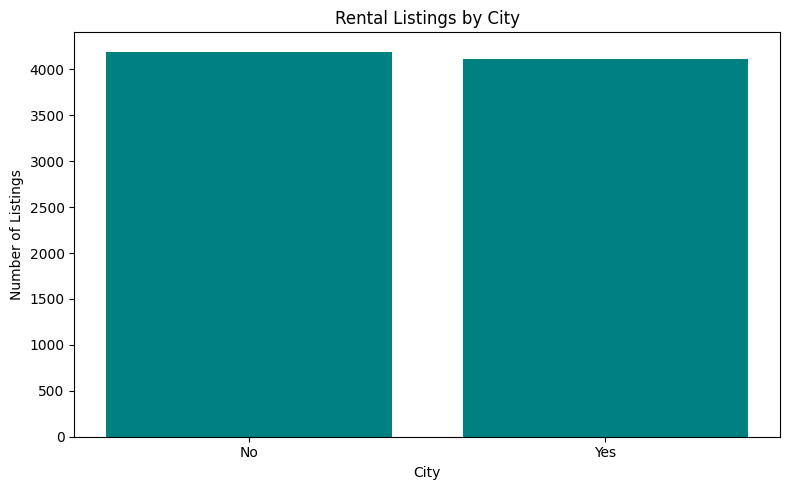

In [116]:
city_counts = df['Extracurricular Activities'].value_counts()
plt.figure(figsize=(8, 5))
plt.bar(city_counts.index, city_counts.values, color='teal')
plt.title('Rental Listings by City')
plt.xlabel('City')
plt.ylabel('Number of Listings')
plt.tight_layout()
plt.show()

In [117]:
imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
df[['Extracurricular Activities']] = imputer.fit_transform(df[['Extracurricular Activities']])


In [118]:
df['Extracurricular Activities'].isnull().sum()

np.int64(0)

In [119]:
df.isnull().sum().sort_values(ascending=False).head(12)

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

In [120]:
df.select_dtypes(include=['object']).columns

Index(['Extracurricular Activities'], dtype='object')

In [121]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown='ignore')
ohe_encoded = ohe.fit_transform(df[['Extracurricular Activities']]).toarray()

In [122]:
ohe_df = pd.DataFrame(
    ohe_encoded,
    columns=ohe.get_feature_names_out(['Extracurricular Activities']),
    index=df.index
)

df = pd.concat([df, ohe_df], axis=1)

In [123]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index,Extracurricular Activities_No,Extracurricular Activities_Yes
0,7,99,Yes,9,1.0,91,0.0,1.0
1,4,82,No,4,2.0,65,1.0,0.0
2,8,51,Yes,7,2.0,45,0.0,1.0
3,5,52,Yes,5,2.0,36,0.0,1.0
4,7,75,No,8,5.0,66,1.0,0.0


In [124]:
df.drop(['Extracurricular Activities'], axis = 1 , inplace = True)

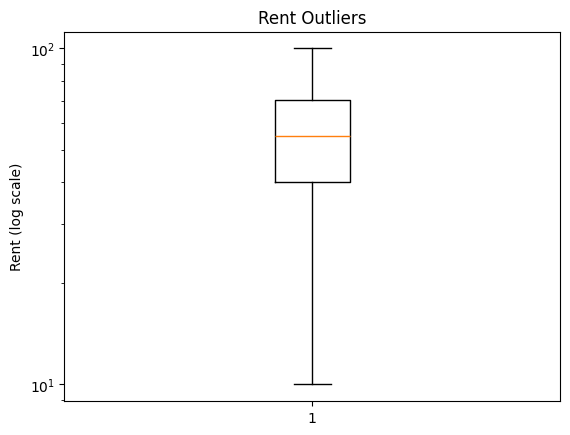

In [125]:
plt.boxplot(df['Performance Index'])
plt.yscale('log')
plt.ylabel('Rent (log scale)')
plt.title('Rent Outliers')
plt.show()

In [126]:
from sklearn.preprocessing import StandardScaler , MinMaxScaler


In [127]:
df.head(30)

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index,Extracurricular Activities_No,Extracurricular Activities_Yes
0,7,99,9,1.000000,91,0.0,1.0
1,4,82,4,2.000000,65,1.0,0.0
2,8,51,7,2.000000,45,0.0,1.0
3,5,52,5,2.000000,36,0.0,1.0
4,7,75,8,5.000000,66,1.0,0.0
5,3,78,9,6.000000,61,1.0,0.0
6,7,73,5,6.000000,63,0.0,1.0
7,8,45,4,4.574894,42,0.0,1.0
8,5,77,8,4.574894,61,1.0,0.0
9,4,89,4,4.574894,69,1.0,0.0


In [128]:
X = df.drop(['Performance Index'], axis=1)
X.head()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Extracurricular Activities_No,Extracurricular Activities_Yes
0,7,99,9,1.0,0.0,1.0
1,4,82,4,2.0,1.0,0.0
2,8,51,7,2.0,0.0,1.0
3,5,52,5,2.0,0.0,1.0
4,7,75,8,5.0,1.0,0.0


In [129]:
df.reset_index(drop=True, inplace=True)

In [130]:
y = df['Performance Index']
y.head()

0    91
1    65
2    45
3    36
4    66
Name: Performance Index, dtype: int64

In [131]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=100
)

print('X_train = ', X_train.shape, ' y_train = ', y_train.shape)
print('X_test  = ', X_test.shape, ' y_test  = ', y_test.shape)

X_train =  (7894, 6)  y_train =  (7894,)
X_test  =  (1974, 6)  y_test  =  (1974,)


In [132]:
from sklearn.preprocessing import MinMaxScaler

my_scaler = MinMaxScaler(feature_range=(0, 100))
X_train[['Previous Scores']] = my_scaler.fit_transform(X_train[['Previous Scores']])
X_test[['Previous Scores']] = my_scaler.transform(X_test[['Previous Scores']])

In [133]:
my_scaler = StandardScaler()
X_train[['Sleep Hours']] = my_scaler.fit_transform(X_train[['Sleep Hours']])
X_test[['Sleep Hours']] = my_scaler.transform(X_test[['Sleep Hours']])

In [134]:
X_train.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Extracurricular Activities_No,Extracurricular Activities_Yes
count,7894.000000,7894.000000,7.894000e+03,7894.000000,7894.000000,7894.000000
mean,5.001013,50.061622,-2.016235e-16,4.559832,0.581834,0.418166
std,2.600763,29.291565,1.000063e+00,2.442115,0.493289,0.493289
min,1.000000,0.000000,-1.487631e+00,0.000000,0.000000,0.000000
25%,3.000000,25.423729,-8.989327e-01,3.000000,0.000000,0.000000
50%,5.000000,50.847458,2.784648e-01,4.574894,1.000000,0.000000
75%,7.000000,76.271186,8.671636e-01,6.000000,1.000000,1.000000
max,9.000000,100.000000,1.455862e+00,9.000000,1.000000,1.000000


In [135]:
y_train.head()

5167    26
787     88
2880    35
1399    23
3250    49
Name: Performance Index, dtype: int64

In [136]:
X_test.head()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Extracurricular Activities_No,Extracurricular Activities_Yes
2614,2,18.644068,-1.487631,4.574894,1.0,0.0
5855,9,27.118644,-0.898933,9.000000,1.0,0.0
7668,1,23.728814,-0.310234,1.000000,1.0,0.0
9750,7,57.627119,-0.898933,7.000000,0.0,1.0
1243,1,62.711864,1.455862,4.574894,1.0,0.0


In [137]:
y_test.head()

2614    30
5855    52
7668    27
9750    68
1243    57
Name: Performance Index, dtype: int64

In [138]:
from sklearn.linear_model import LinearRegression

In [139]:
model = LinearRegression(
    fit_intercept=True,
    copy_X=True,
    n_jobs=None,
    positive=False
)

In [140]:
from sklearn.linear_model import Ridge

In [141]:
model = Ridge()

In [142]:
model.fit(X_train , y_train)

Ridge()

In [143]:
y_pred = model.predict(X_test)

In [144]:
y_pred[:5]

array([26.4339641 , 52.94493447, 26.86442358, 65.67622328, 52.42626213])

In [145]:
from sklearn.metrics import r2_score , mean_absolute_error , mean_squared_error


In [146]:
mr2 = r2_score(y_test , y_pred)
mr2

0.9879087144636911

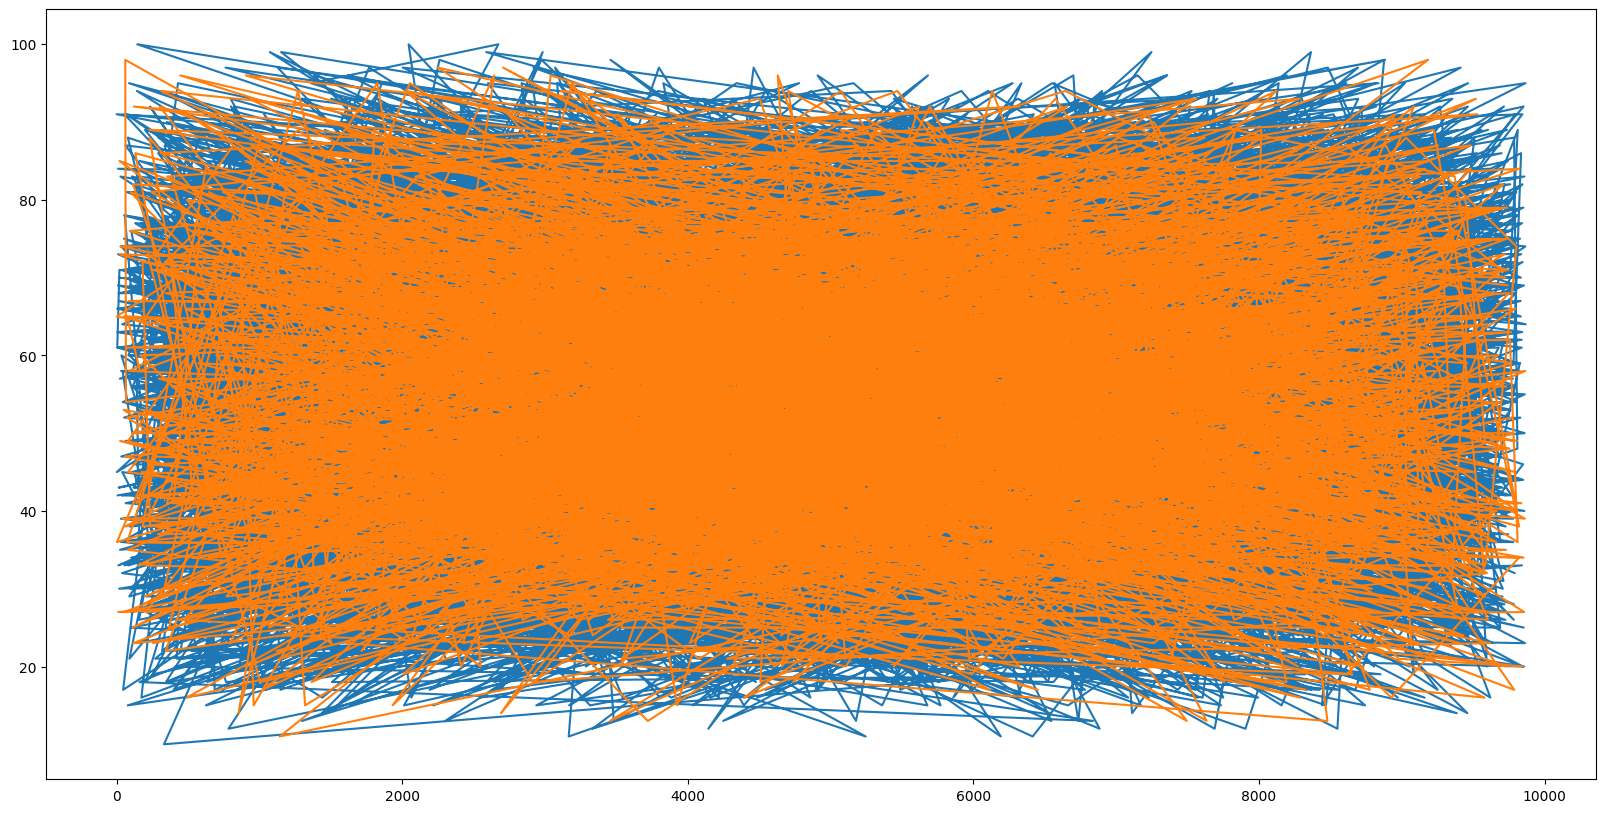

In [151]:
plt.figure(figsize=(20,10))
plt.plot(y_train)
plt.plot(y_test)

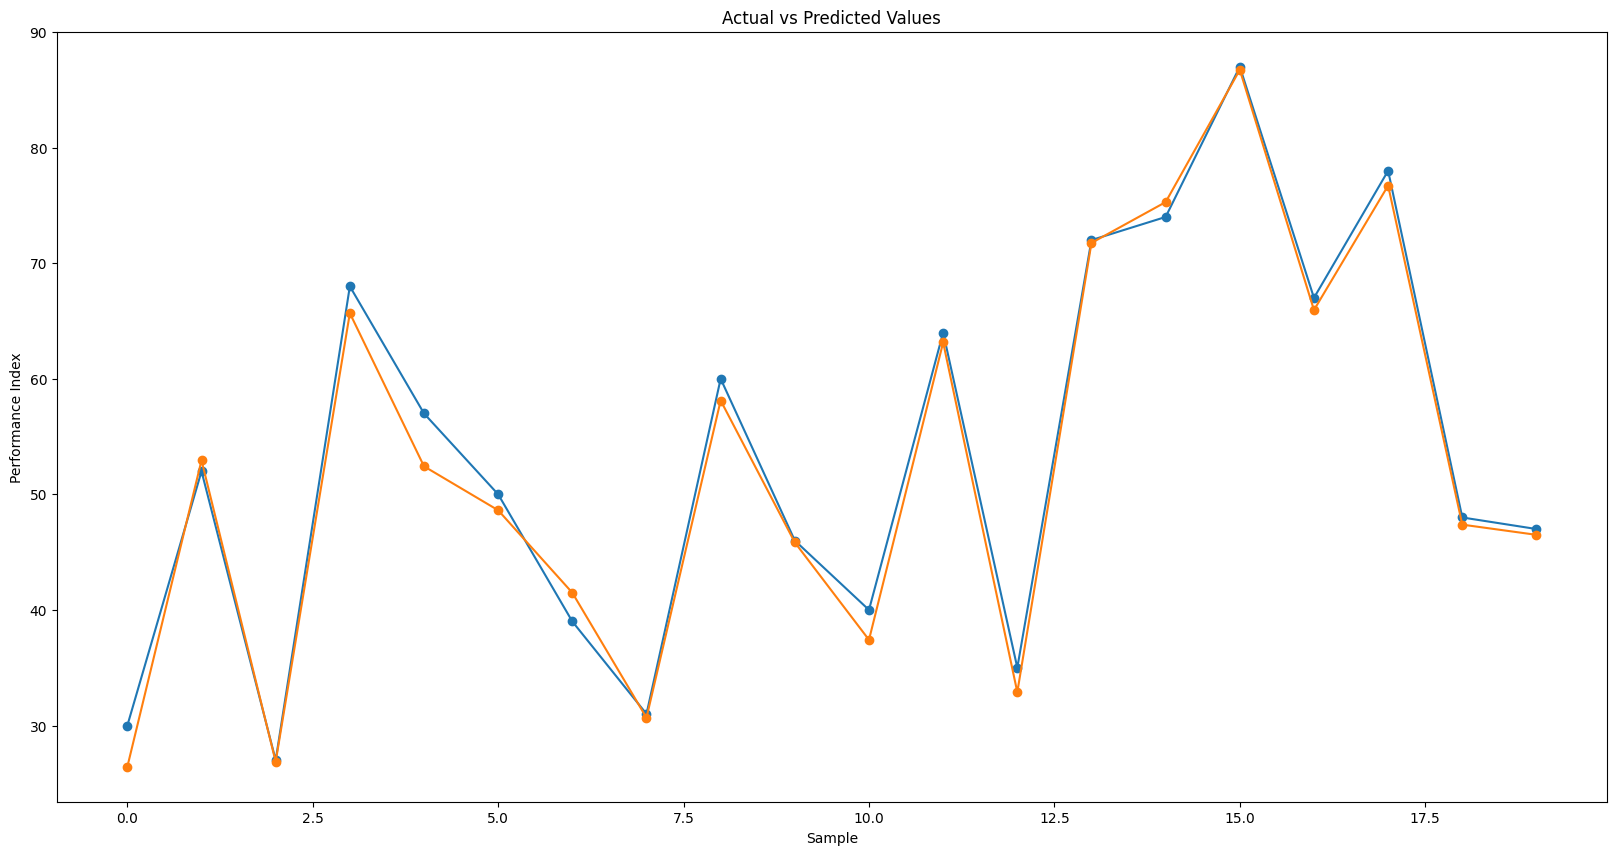

In [153]:
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))
plt.plot(y_test.values[:20], marker='o', label='Actual')
plt.plot(y_pred[:20], marker='o', label='Predicted')

plt.xlabel('Sample')
plt.ylabel('Performance Index')
plt.title('Actual vs Predicted Values')

plt.show()